In [1]:
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker # used for percentage ticks
import matplotlib.colors as mcolors

# Stats
from scipy.stats import linregress
import statsmodels.formula.api as smf

In [2]:
from analysis import *

There are 3 real clones that have < 2 observation times.


## Linear Model

In [3]:
def linear_model(df, dep_var, scenario, duplicate):
    df2 = df.query('scenario == @scenario and ~r_opt.isna() and duplicate == @duplicate').copy()
    slope, intercept, r, p, stderr = linregress(df2['init_freq'], df2[dep_var])

    return slope, intercept, r, p, stderr, df2

dep_var = 'symlog10_r'
scenario = 'full_pipeline'
slope, intercept, r, p, stderr, df2 = linear_model(df, dep_var, scenario, 0)

print(f'The p value for scenario \'{scenario}\' is p={p:.2e}.')

The p value for scenario 'full_pipeline' is p=6.47e-14.


In [4]:
def p_table(scenario):
    rows = []
    for duplicate in df[df['scenario'] == scenario]['duplicate'].unique():
        slope, intercept, r, p, stderr, df2 = linear_model(df, 'symlog10_r', scenario, duplicate)
        row = {'Duplicate': duplicate, 'p': p}
        rows.append(row)
    
    results_df = pd.DataFrame(rows)
    return results_df

In [5]:
# Fit the linear model over 10 different runs of the model.
# You can change the scenario input to see how different simulations affect the p value.
# For example, input 'r36_rp3_mimic' to see the results for simulations with drift rate 3.
p_table('r36_rp2_mimic')

,Duplicate,p
0,0,0.614446
1,1,0.836076
2,2,0.899570
3,3,0.305926
4,4,0.337853
5,5,0.004774
6,6,0.498891
7,7,0.443088
8,8,0.606853
9,9,0.688855


## Generate Figure Plot

In [6]:
def panel(ax, df, scenario, label, duplicate, color):
    duplicate = 0
    slope, intercept, r, p, stderr, df2 = linear_model(df, 'symlog10_r', scenario, duplicate)
    
    x = np.linspace(0, 1, 200)
    y = intercept + slope * x

    ax.plot(x, y, color = 'black', linewidth = 2)
    ax.scatter(df2['init_freq'], df2[dep_var], color = palette[label], alpha=0.8,
                  edgecolor='black', linewidth=0.5, s = 15)
    
    ax.set_title(label)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
    ax.text(0.95, 0.1, format_p(p),
             transform=ax.transAxes, ha='right', va='bottom', fontsize=6)
    ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray')
    ax.set_axisbelow(True) 
    ax.set_xlim([0, 1])

In [7]:
def format_p(p):
    if p < 1e-3:
        mantissa, exponent = f"{p:.2e}".split("e")
        exponent = int(exponent)
        return rf"$p = {mantissa} \times 10^{{{exponent}}}$"
    else:
        return rf"$p = {p:.2g}$"

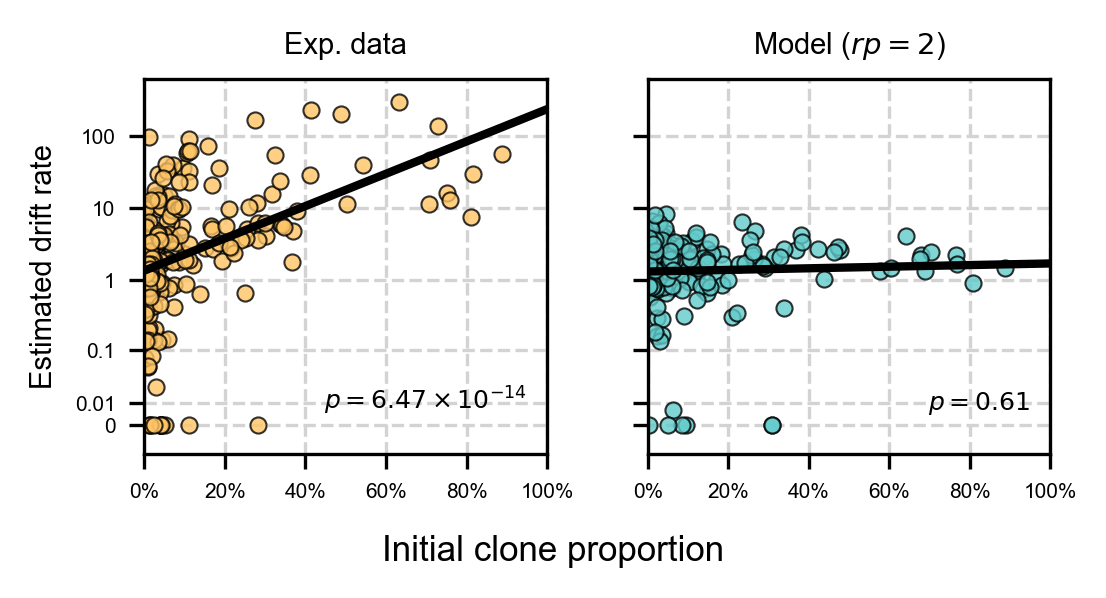

In [11]:
plt.rcParams.update(small_label_settings)

supplement_mode = False

if supplement_mode:
    scenarios = ['full_pipeline', 'full_pipeline_TQ14', 'full_pipeline_MP0.95', 'no_cluster', 'r36_rp2_mimic']
    labels = ['Exp. data', 'Exp. data (TQ 14)', 'Exp. data (MP 0.95)', 'Exp. data (no cluster)', 'Model ($rp=2$)']
    fig, ax = plt.subplots(1, 5, figsize = (6.5, 1.5), dpi = 300, sharey = True)    
    filepath = os.path.join('images', 'correlation_supplement.svg')
else:
    scenarios = ['full_pipeline', 'r36_rp2_mimic']
    labels = ['Exp. data', 'Model ($rp=2$)']
    fig, ax = plt.subplots(1, 2, figsize = (3.7, 2), dpi = 300, sharey = True)    
    filepath = os.path.join('images', 'correlation.svg')

for i, (scenario, label) in enumerate(zip(scenarios, labels)):
    duplicate = 0
    panel(ax[i], df, scenario, label, duplicate, palette[label])

ax[0].set_ylabel("Estimated drift rate")

tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
ax[0].set_ylim([-0.4, 4.8])
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
ax[0].set_yticks(tick_symlog)
ax[0].set_yticklabels([str(r) for r in tick_r])

fig.supxlabel("Initial clone proportion", y = 0.05)

plt.tight_layout()
plt.subplots_adjust(wspace=0.25)   # smaller = tighter spacing

plt.savefig(filepath, bbox_inches = 'tight', pad_inches = 0)

## Linear Mixed Model
Below are linear models that fit a line to both simulated and experimental data with an interaction term. This is not discussed in the paper but has a similar result as the earlier linear models: the model does not significantly depend on initial clone size but the interaction term is significant.

In [11]:
def linear_mm(df, exp_scenario, sim_scenario, sim_duplicate):
    df2 = df[
        (df['scenario'] == exp_scenario) |
        ((df['scenario'] == sim_scenario) & (df['duplicate'] == sim_duplicate))
    ].copy()

    # Set scenario as categorial and re-order.
    df2['scenario'] = pd.Categorical(df2['scenario'])
    df2['scenario'] = df2['scenario'].cat.reorder_categories(
        [sim_scenario, exp_scenario]
    )
    
    # Center data
    df2['init_freq_c'] = df2['init_freq']  - df2['init_freq'].mean()
    df2['log_r_c']     = df2['symlog10_r'] - df2['symlog10_r'].mean()

    model = smf.mixedlm(
        "log_r_c ~ init_freq_c * scenario",
        data=df2,
        groups=df2["fish"],
        re_formula="~1"
    ).fit(method="lbfgs")
    return model, df2

In [12]:
exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

model, df2 = linear_mm(df, exp_scenario, sim_scenario, 0)
model.summary()

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


<class 'statsmodels.iolib.summary2.Summary'>
"""
                     Mixed Linear Model Regression Results
================================================================================
Model:                     MixedLM         Dependent Variable:         log_r_c  
No. Observations:          451             Method:                     REML     
No. Groups:                24              Scale:                      0.4140   
Min. group size:           5               Log-Likelihood:             -456.4567
Max. group size:           30              Converged:                  Yes      
Mean group size:           18.8                                                 
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                             -0.105    0.066 -1.577 0.115 -0.235  0.025
scenario[T.full_pipeline]              0.228    0.063  3.603 0.000  0.104  0.352
init_freq_c                            0.036    0.267  0.134 0.893 -0.487  0.559
init_freq_c:scenario[T.full_pipeline]  2.162    0.359  6.016 0.000  1.458  2.867
Group Var                              0.043    0.032                           
================================================================================

"""

In [13]:
print(f"The significance of initial frequency on simulated data is {model.pvalues['init_freq_c']:.3g}.")
print(f"The significance of interaction on initial frequency is {model.pvalues['init_freq_c:scenario[T.full_pipeline]']:.3g}.")

The significance of initial frequency on simulated data is 0.893.
The significance of interaction on initial frequency is 1.78e-09.


In [14]:
exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

rows = []
for d in df['duplicate'].unique():
    model, df2 = linear_mm(df, exp_scenario, sim_scenario, d)
    interact_p = model.pvalues[f'init_freq_c:scenario[T.{exp_scenario}]']
    sim_p = model.pvalues['init_freq_c']
    
    # print(f'For duplicate {d}, the simulation p is {sim_p:.3g} and the interaction p is {interact_p:.3g}.')
    row = {'Duplicate': d, 'simulation p': sim_p, 'interaction p': interact_p}
    rows.append(row)

results_df = pd.DataFrame(rows)
results_df

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.p

,Duplicate,simulation p,interaction p
0,0,0.893341,1.783107e-09
1,1,0.730353,1.117433e-10
2,2,0.525289,2.274163e-11
3,3,0.249156,9.737938e-13
4,4,0.788755,2.627966e-09
5,5,0.003565,7.725282e-17
6,6,0.282683,4.052896e-12
7,7,0.879141,3.258524e-09
8,8,0.431360,7.433683e-12
9,9,0.658494,6.878421e-11
